# Assignment 3 — Car Resale Value Prediction with Regularization

**Scenario:** A car-manufacturing company wants to predict the resale value of
cars. Because the data has many correlated features (high variance / overfitting),
they want to apply **regularization** techniques.

**Dataset:** `CarPrice_Assignment.csv` (Kaggle: *hellbuoy/car-price-prediction*,
205 rows, 26 columns).

**Approach:** Compare plain Linear Regression against **Ridge (L2)**,
**Lasso (L1)**, and **ElasticNet** regularization. We deliberately expand the
feature space with polynomial terms to *induce* overfitting, then show how
regularization controls it. Hyper-parameters are tuned with cross-validation.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.exceptions import ConvergenceWarning

# Lasso/ElasticNet CV explore very small alphas on an intentionally over-sized
# feature space, which triggers benign convergence/unknown-category warnings.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid")
np.random.seed(42)

df = pd.read_csv("../data/CarPrice_Assignment.csv")
print("Shape:", df.shape)
df.head()

Shape: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## 1. Clean & engineer features

- `car_ID` is an identifier → drop it.
- `CarName` begins with the brand but has typos (e.g. *maxda* → *mazda*). We
  extract and clean the **brand** as a categorical feature and drop the raw name.

In [2]:
df = df.drop(columns=["car_ID"])

df["brand"] = df["CarName"].str.split(" ").str[0].str.lower()
fix = {"maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
       "vokswagen": "volkswagen", "vw": "volkswagen"}
df["brand"] = df["brand"].replace(fix)
df = df.drop(columns=["CarName"])

print("Missing values:", int(df.isna().sum().sum()))
print("Brands:", df["brand"].nunique())
df["brand"].value_counts().head()

Missing values: 0
Brands: 22


brand
toyota        32
nissan        18
mazda         17
honda         13
mitsubishi    13
Name: count, dtype: int64

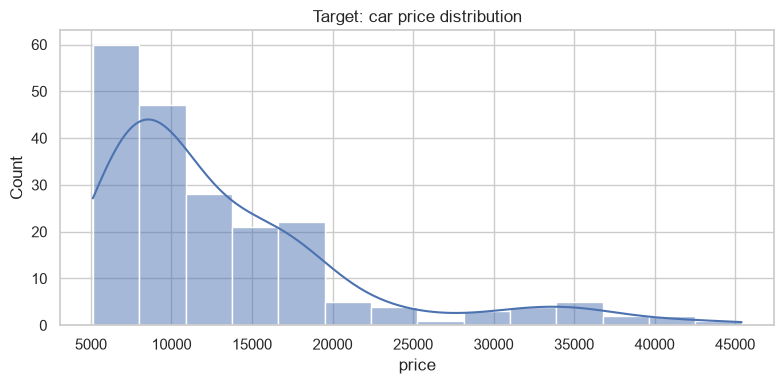

In [3]:
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], kde=True, color="#4C72B0")
plt.title("Target: car price distribution"); plt.tight_layout(); plt.show()

## 2. Correlation among numeric features (motivation for regularization)

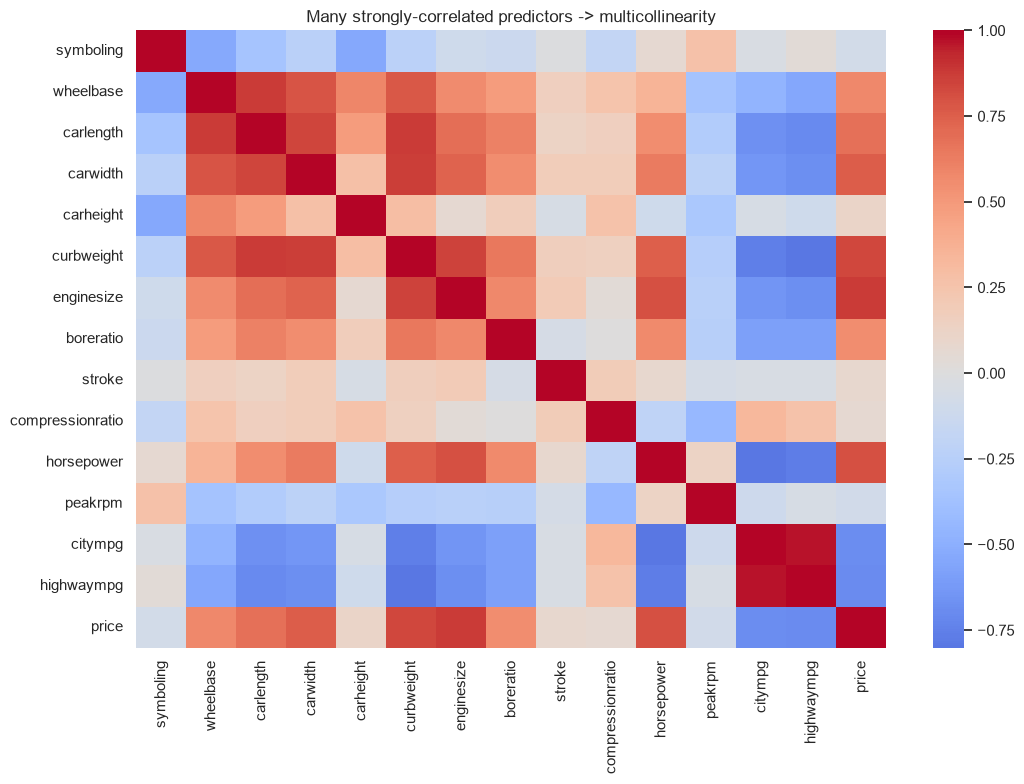

Highly correlated feature pairs (|r| > 0.8):
citympg     highwaympg    0.971337
carlength   curbweight    0.877728
wheelbase   carlength     0.874587
enginesize  price         0.874145
carwidth    curbweight    0.867032
curbweight  enginesize    0.850594
carlength   carwidth      0.841118
curbweight  price         0.835305
enginesize  horsepower    0.809769
horsepower  price         0.808139
            citympg       0.801456
dtype: float64


In [4]:
num = df.select_dtypes("number")
plt.figure(figsize=(11, 8))
sns.heatmap(num.corr(), annot=False, cmap="coolwarm", center=0)
plt.title("Many strongly-correlated predictors -> multicollinearity")
plt.tight_layout(); plt.show()

print("Highly correlated feature pairs (|r| > 0.8):")
cm = num.corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool))
           .stack().sort_values(ascending=False))
print(pairs[pairs > 0.8])

## 3. Preprocessing

Numeric features are scaled and expanded with **degree-2 polynomial features**
(this inflates the feature count and encourages overfitting). Categorical features
are one-hot encoded.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=["price"])
y = df["price"]

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()

pre = ColumnTransformer([
    ("num", Pipeline([("scale", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
n_feats = pre.fit_transform(X_train).shape[1]
print(f"Feature count after expansion: {n_feats}  (train rows: {X_train.shape[0]})")
print("-> far more features than rows in places: overfitting is likely.")

Feature count after expansion: 168  (train rows: 164)
-> far more features than rows in places: overfitting is likely.


/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_7099/3957403612.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes("object").columns.tolist()


## 4. Baseline vs regularized models

`RidgeCV`, `LassoCV`, and `ElasticNetCV` pick their regularization strength
`alpha` by cross-validation automatically.

In [6]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error

alphas = np.logspace(-3, 4, 60)

models = {
    "Linear (no reg)": LinearRegression(),
    "Ridge (L2)": RidgeCV(alphas=alphas),
    "Lasso (L1)": LassoCV(alphas=alphas, max_iter=50000, random_state=42),
    "ElasticNet": ElasticNetCV(alphas=alphas, l1_ratio=[.2, .5, .8],
                               max_iter=50000, random_state=42),
}

rows = []
fitted = {}
for name, est in models.items():
    pipe = Pipeline([("pre", pre), ("reg", est)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    tr = r2_score(y_train, pipe.predict(X_train))
    te = r2_score(y_test, pipe.predict(X_test))
    rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
    rows.append({"model": name, "train_R2": tr, "test_R2": te,
                 "gap(overfit)": tr - te, "test_RMSE": rmse})

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,train_R2,test_R2,gap(overfit),test_RMSE
model,,,,
Linear (no reg),0.999,-478.867,479.866,194634.690
Ridge (L2),0.963,0.869,0.093,3211.340
Lasso (L1),0.958,0.886,0.072,2999.670
ElasticNet,0.955,0.856,0.099,3369.922


The **gap between train and test R²** measures overfitting. Plain linear
regression fits the training set almost perfectly but generalizes poorly;
regularization shrinks the gap and improves (or stabilizes) test performance.

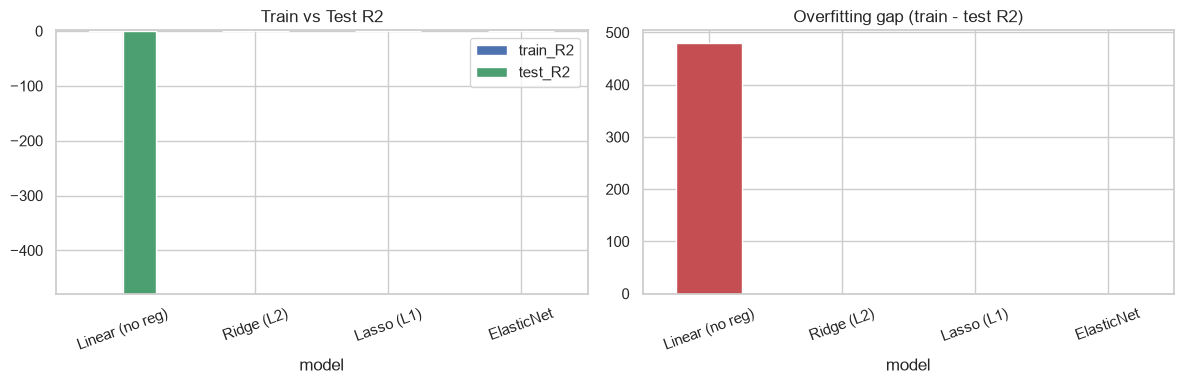

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[["train_R2", "test_R2"]].plot.bar(ax=axes[0], color=["#4C72B0", "#4C9F70"])
axes[0].set_title("Train vs Test R2"); axes[0].set_ylim(min(0, results[["train_R2","test_R2"]].values.min()), 1.05)
axes[0].tick_params(axis="x", rotation=20)
results["gap(overfit)"].plot.bar(ax=axes[1], color="#C44E52")
axes[1].set_title("Overfitting gap (train - test R2)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 5. Effect of alpha on Ridge coefficients

As the regularization strength `alpha` grows, coefficients shrink toward zero —
this is the mechanism that reduces variance.

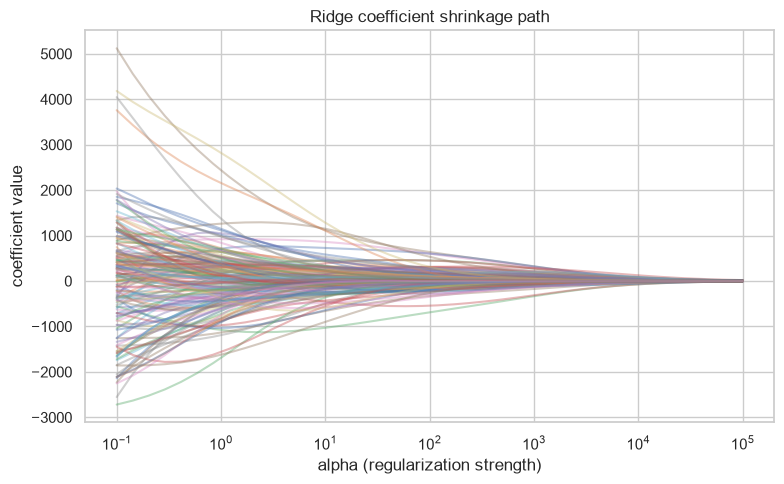

In [8]:
from sklearn.linear_model import Ridge

Xtr_t = pre.fit_transform(X_train)
coefs = []
alpha_grid = np.logspace(-1, 5, 40)
for a in alpha_grid:
    r = Ridge(alpha=a).fit(Xtr_t, y_train)
    coefs.append(r.coef_)
coefs = np.array(coefs)

plt.figure(figsize=(8, 5))
plt.plot(alpha_grid, coefs, alpha=0.4)
plt.xscale("log")
plt.xlabel("alpha (regularization strength)"); plt.ylabel("coefficient value")
plt.title("Ridge coefficient shrinkage path")
plt.tight_layout(); plt.show()

## 6. Lasso performs feature selection

In [9]:
lasso = fitted["Lasso (L1)"].named_steps["reg"]
n_zero = int(np.sum(lasso.coef_ == 0))
print(f"Lasso selected alpha = {lasso.alpha_:.3f}")
print(f"Coefficients driven to exactly zero: {n_zero} of {len(lasso.coef_)}")
print("-> Lasso automatically discards redundant/collinear features.")

Lasso selected alpha = 96.172
Coefficients driven to exactly zero: 133 of 168
-> Lasso automatically discards redundant/collinear features.


## Conclusion

- The polynomial-expanded feature space makes plain **Linear Regression overfit**
  (near-perfect train R², much lower test R²).
- **Ridge, Lasso, and ElasticNet** all reduce the train–test gap. Regularization
  trades a little training fit for substantially better generalization.
- **Lasso** additionally zeroes out many correlated/irrelevant coefficients,
  giving a simpler, more interpretable model — well suited to this
  high-multicollinearity dataset.
- The coefficient path confirms the core idea: larger `alpha` → smaller
  coefficients → lower variance.
